<table class="table table-bordered">
    <tr>
        <th style="text-align:center; vertical-align: middle; width:50%"><img src='https://www.np.edu.sg/_next/image?url=https%3A%2F%2Fassets.app.optical.gov.sg%2Fnp%2Fproduction%2Fpublished%2Fcollections%2Fpages%2F17c64bb4-8632-49e9-af16-047f7cabe99a%2Fab16008f-a6a0-466e-9193-e16e947261b0.png&w=640&q=75'"></th>
        <th style="text-align:center;"><h1>Deep Learning</h1><h2>Assignment 1 - Food Classification Model (Individual)</h2><h3>AY2026/27 Semester</h3></th>
    </tr>
</table>

In [1]:
# Import the Required Packages
import os
import keras
from keras.utils import image_dataset_from_directory

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from keras.applications import VGG16
from keras.applications.vgg16 import preprocess_input #for data aug
from keras import layers
from keras import Input
from keras import models
from keras import optimizers
from keras.regularizers import l2
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

<br>
Create function to plot accuracy and loss curves.

In [31]:
def plot_curves(history, title=''):
    h = history.history if hasattr(history, 'history') else history
    acc, val_acc = h['acc'], h['val_acc']
    loss, val_loss = h['loss'], h['val_loss']
    epochs = range(1, len(acc)+1)

    plt.figure()
    plt.plot(epochs, acc, 'bo', label='Training acc')
    plt.plot(epochs, val_acc, 'b', label='Validation acc')
    plt.title(f'Training and validation accuracy ({title})')
    plt.legend()

    plt.figure()
    plt.plot(epochs, loss, 'bo', label='Training loss')
    plt.plot(epochs, val_loss, 'b', label='Validation loss')
    plt.title(f'Training and validation loss ({title})')
    plt.legend()

    plt.show()

## Step 1: Data Loading

In [3]:
base_dir = r"C:\Users\jaeth\Downloads\NP\Y2S1\DL\DL ASG\ASG Task2 Data"

train_dir = os.path.join(base_dir, 'train')
validation_dir = os.path.join(base_dir, 'validation')
test_dir = os.path.join(base_dir, 'test')

batch_size = 20
img_size = 100
image_size = (img_size, img_size)

train_dataset = image_dataset_from_directory(
		train_dir, image_size=image_size, batch_size=batch_size
)
validation_dataset = image_dataset_from_directory(
		validation_dir, image_size=image_size, batch_size=batch_size
)
test_dataset = image_dataset_from_directory(
		test_dir, image_size=image_size, batch_size=batch_size)

Found 7500 files belonging to 10 classes.
Found 2000 files belonging to 10 classes.
Found 500 files belonging to 10 classes.


## Step 2:  Develop the Image Classification Models

### Model #1

In [3]:
# Build the Model
sModel = models.Sequential()

sModel.add(Input(shape=(img_size, img_size, 3)))
sModel.add(layers.Rescaling(1/255))
sModel.add(layers.Conv2D(32, 3, activation='relu'))
sModel.add(layers.MaxPooling2D(2))

sModel.add(layers.Conv2D(64, 3, activation='relu'))
sModel.add(layers.MaxPooling2D(2))

sModel.add(layers.Conv2D(128, 3, activation='relu'))
sModel.add(layers.MaxPooling2D(2))

sModel.add(layers.Conv2D(128, 3, activation='relu'))
sModel.add(layers.MaxPooling2D(2))

sModel.add(layers.Flatten())
sModel.add(layers.Dense(256, activation='relu'))
sModel.add(layers.Dense(10, activation='softmax'))

sModel.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 767,946 (2.93 MB)

 Trainable params: 767,946 (2.93 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Train the Model
sModel.compile(optimizer='adam', 
               loss='sparse_categorical_crossentropy', 
               metrics=['acc'])

hist = sModel.fit(train_dataset,
                  epochs=20,
                  validation_data=validation_dataset)

Epoch 1/20


c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


375/375 ━━━━━━━━━━━━━━━━━━━━ 28s 67ms/step - acc: 0.1932 - loss: 2.1683 - val_acc: 0.2580 - val_loss: 2.0336
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 27s 73ms/step - acc: 0.2948 - loss: 1.9659 - val_acc: 0.3175 - val_loss: 1.8858
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 30s 79ms/step - acc: 0.3564 - loss: 1.8203 - val_acc: 0.3395 - val_loss: 1.8229
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 35s 93ms/step - acc: 0.4141 - loss: 1.6712 - val_acc: 0.3685 - val_loss: 1.7701
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 35s 94ms/step - acc: 0.4644 - loss: 1.5452 - val_acc: 0.3990 - val_loss: 1.7085
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 31s 82ms/step - acc: 0.5161 - loss: 1.3982 - val_acc: 0.4085 - val_loss: 1.7042
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 32s 85ms/step - acc: 0.5616 - loss: 1.2557 - val_acc: 0.3995 - val_loss: 1.8136
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 33s 89ms/step - acc: 0.6157 - loss: 1.0903 - val_acc: 0.3960 - val_loss: 1.8852
Epoch 9/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 32s 86ms/st

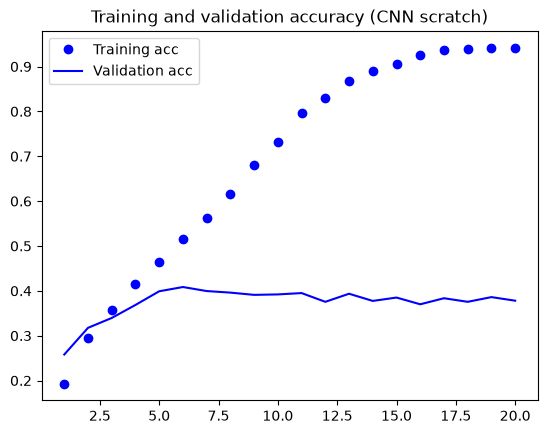

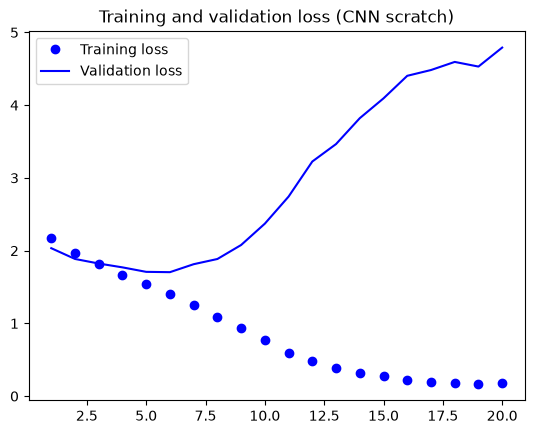

In [32]:
# Plot the Training and Validation Accuracy & Loss Scores
plot_curves(hist, 'CNN scratch')

#### Attempt 1: Add data augmentation + dropout (0.5)

In [6]:
data_augmentation_layers = [
		layers.RandomFlip('horizontal'),
		layers.RandomRotation([-0.1, 0.1], fill_mode='nearest'), 
		layers.RandomZoom(0.2, 0.2, fill_mode='nearest')
]

def data_augmentation(images, targets): 
		for layer in data_augmentation_layers:
				images = layer(images, training=True)
		return images, targets

augmented_train_dataset = train_dataset.map(data_augmentation, num_parallel_calls=8)

In [7]:
sModelAug = models.Sequential()

sModelAug.add(Input(shape=(img_size, img_size, 3)))
sModelAug.add(layers.Rescaling(1/255))
sModelAug.add(layers.Conv2D(32, 3, activation='relu'))
sModelAug.add(layers.MaxPooling2D(2))

sModelAug.add(layers.Conv2D(64, 3, activation='relu'))
sModelAug.add(layers.MaxPooling2D(2))

sModelAug.add(layers.Conv2D(128, 3, activation='relu'))
sModelAug.add(layers.MaxPooling2D(2))

sModelAug.add(layers.Conv2D(128, 3, activation='relu'))
sModelAug.add(layers.MaxPooling2D(2))

sModelAug.add(layers.Flatten())
sModelAug.add(layers.Dropout(0.5))
sModelAug.add(layers.Dense(256, activation='relu'))
sModelAug.add(layers.Dense(10, activation='softmax'))


sModelAug.compile(loss='sparse_categorical_crossentropy',
              optimizer=optimizers.Adam(learning_rate=1e-4),
              metrics=['acc'])

histAug = sModelAug.fit(
        augmented_train_dataset,
        epochs=30,
        validation_data=validation_dataset)

Epoch 1/30


c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


375/375 ━━━━━━━━━━━━━━━━━━━━ 35s 83ms/step - acc: 0.1731 - loss: 2.2081 - val_acc: 0.1980 - val_loss: 2.1954
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 36s 96ms/step - acc: 0.2551 - loss: 2.0396 - val_acc: 0.2715 - val_loss: 1.9936
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 33s 88ms/step - acc: 0.2861 - loss: 1.9840 - val_acc: 0.2820 - val_loss: 1.9714
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 37s 97ms/step - acc: 0.3163 - loss: 1.9248 - val_acc: 0.2815 - val_loss: 1.9877
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 36s 96ms/step - acc: 0.3371 - loss: 1.8625 - val_acc: 0.3330 - val_loss: 1.8371
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 37s 99ms/step - acc: 0.3652 - loss: 1.8167 - val_acc: 0.3495 - val_loss: 1.8707
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 38s 100ms/step - acc: 0.3779 - loss: 1.7750 - val_acc: 0.3770 - val_loss: 1.7440
Epoch 8/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - acc: 0.3965 - loss: 1.7258 - val_acc: 0.3715 - val_loss: 1.8208
Epoch 9/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 37s 99ms/

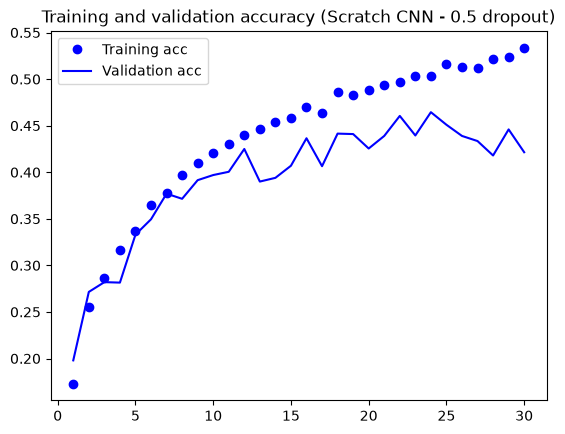

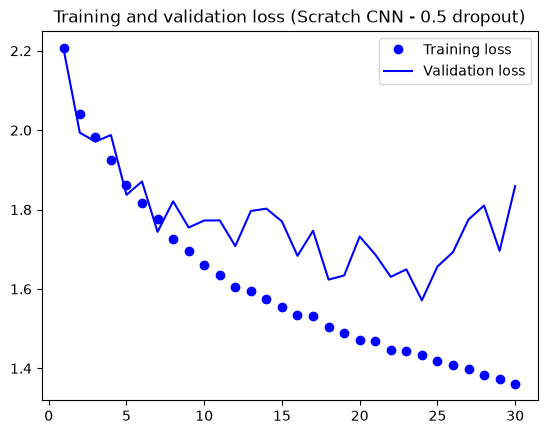

In [33]:
# Plot the Training and Validation Accuracy & Loss Scores
plot_curves(histAug, 'Scratch CNN - 0.5 dropout')

#### Attempt 2: Dropout (0.3) + EarlyStopping

In [13]:
sModelAug2 = models.Sequential()
sModelAug2.add(Input(shape=(img_size, img_size, 3)))
sModelAug2.add(layers.Rescaling(1/255))
sModelAug2.add(layers.Conv2D(32, 3, activation='relu'))
sModelAug2.add(layers.MaxPooling2D(2))
sModelAug2.add(layers.Conv2D(64, 3, activation='relu'))
sModelAug2.add(layers.MaxPooling2D(2))
sModelAug2.add(layers.Conv2D(128, 3, activation='relu'))
sModelAug2.add(layers.MaxPooling2D(2))
sModelAug2.add(layers.Conv2D(128, 3, activation='relu'))
sModelAug2.add(layers.MaxPooling2D(2))
sModelAug2.add(layers.Flatten())
sModelAug2.add(layers.Dropout(0.3))
sModelAug2.add(layers.Dense(256, activation='relu'))
sModelAug2.add(layers.Dense(10, activation='softmax'))

sModelAug2.compile(loss='sparse_categorical_crossentropy',
                    optimizer=optimizers.Adam(learning_rate=1e-4),
                    metrics=['acc'])

early_stop = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)

histAug2 = sModelAug2.fit(
    augmented_train_dataset,
    epochs=50,
    validation_data=validation_dataset,
    callbacks=[early_stop])

Epoch 1/50


c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


375/375 ━━━━━━━━━━━━━━━━━━━━ 40s 96ms/step - acc: 0.1869 - loss: 2.1810 - val_acc: 0.2320 - val_loss: 2.1001
Epoch 2/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 42s 112ms/step - acc: 0.2663 - loss: 2.0157 - val_acc: 0.2320 - val_loss: 2.1011
Epoch 3/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 42s 111ms/step - acc: 0.3015 - loss: 1.9378 - val_acc: 0.2770 - val_loss: 1.9844
Epoch 4/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 43s 114ms/step - acc: 0.3336 - loss: 1.8783 - val_acc: 0.3405 - val_loss: 1.8408
Epoch 5/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 75s 95ms/step - acc: 0.3667 - loss: 1.8103 - val_acc: 0.3415 - val_loss: 1.9014
Epoch 6/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 110ms/step - acc: 0.3847 - loss: 1.7556 - val_acc: 0.3420 - val_loss: 1.8852
Epoch 7/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 48s 128ms/step - acc: 0.4059 - loss: 1.7114 - val_acc: 0.3895 - val_loss: 1.7557
Epoch 8/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 42s 111ms/step - acc: 0.4169 - loss: 1.6739 - val_acc: 0.4140 - val_loss: 1.7113
Epoch 9/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 39s 1

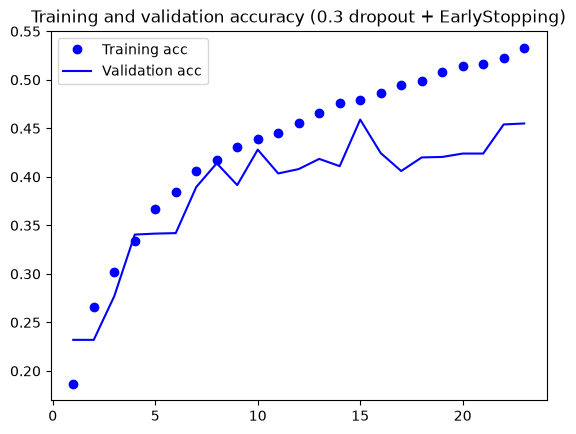

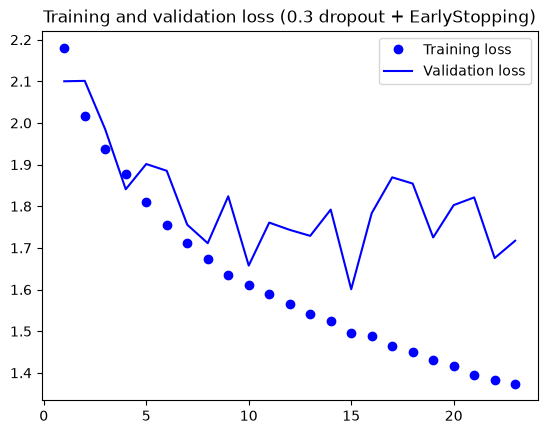

In [34]:
plot_curves(histAug2, '0.3 dropout + EarlyStopping')

### Attempt 3: l2 regularisation, 0.3 dropout, reduce LR, EarlyStop

In [42]:
sModelAug3 = models.Sequential()
sModelAug3.add(Input(shape=(img_size, img_size, 3)))
sModelAug3.add(layers.Rescaling(1/255))

sModelAug3.add(layers.Conv2D(32, 3, activation='relu', kernel_regularizer=l2(1e-4)))
sModelAug3.add(layers.MaxPooling2D(2))

sModelAug3.add(layers.Conv2D(64, 3, activation='relu', kernel_regularizer=l2(1e-4)))
sModelAug3.add(layers.MaxPooling2D(2))

sModelAug3.add(layers.Conv2D(128, 3, activation='relu', kernel_regularizer=l2(1e-4)))
sModelAug3.add(layers.MaxPooling2D(2))

sModelAug3.add(layers.Conv2D(128, 3, activation='relu', kernel_regularizer=l2(1e-4)))
sModelAug3.add(layers.MaxPooling2D(2))

sModelAug3.add(layers.Flatten())
sModelAug3.add(layers.Dropout(0.3))
sModelAug3.add(layers.Dense(256, activation='relu'))
sModelAug3.add(layers.Dropout(0.3))
sModelAug3.add(layers.Dense(10, activation='softmax'))

In [43]:
sModelAug3.compile(optimizer=optimizers.Adam(learning_rate=1e-4),
                   loss='sparse_categorical_crossentropy',
                   metrics=['acc'])

early_stop3 = EarlyStopping(monitor='val_acc', patience=10, restore_best_weights=True)
reduce_lr3 = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6)

histAug3 = sModelAug3.fit(augmented_train_dataset,
                          epochs=60,
                          validation_data=validation_dataset,
                          callbacks=[early_stop3, reduce_lr3])

Epoch 1/60


c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


375/375 ━━━━━━━━━━━━━━━━━━━━ 43s 110ms/step - acc: 0.1732 - loss: 2.2372 - val_acc: 0.2490 - val_loss: 2.0645 - learning_rate: 1.0000e-04
Epoch 2/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 33s 86ms/step - acc: 0.2555 - loss: 2.0611 - val_acc: 0.2495 - val_loss: 2.0738 - learning_rate: 1.0000e-04
Epoch 3/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 31s 82ms/step - acc: 0.2845 - loss: 1.9970 - val_acc: 0.2830 - val_loss: 1.9552 - learning_rate: 1.0000e-04
Epoch 4/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 31s 82ms/step - acc: 0.3161 - loss: 1.9313 - val_acc: 0.3020 - val_loss: 1.9483 - learning_rate: 1.0000e-04
Epoch 5/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 30s 80ms/step - acc: 0.3329 - loss: 1.8888 - val_acc: 0.3240 - val_loss: 1.8784 - learning_rate: 1.0000e-04
Epoch 6/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 33s 87ms/step - acc: 0.3524 - loss: 1.8482 - val_acc: 0.3495 - val_loss: 1.8424 - learning_rate: 1.0000e-04
Epoch 7/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 32s 83ms/step - acc: 0.3737 - loss: 1.7992 - val_acc: 0.3370 - val_loss: 1.8731 - 

In [44]:
sModelAug3.evaluate(augmented_train_dataset)

375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - acc: 0.4949 - loss: 1.5013


[1.5013118982315063, 0.4949333369731903]

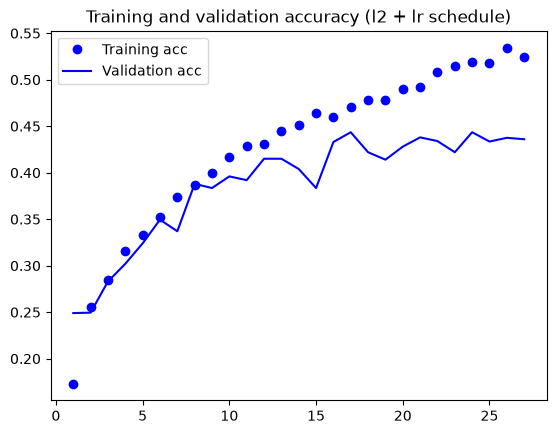

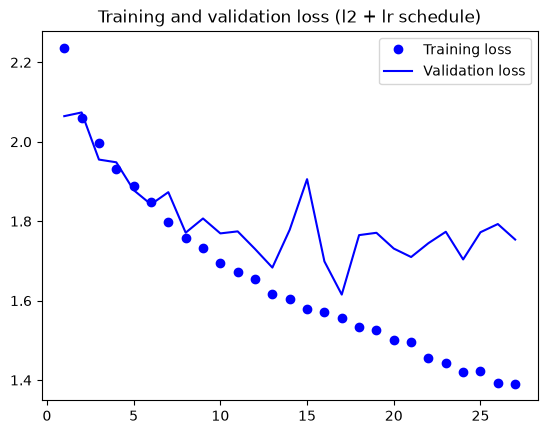

In [46]:
plot_curves(histAug3, 'l2 + lr schedule')

In [47]:
# Save the Model
path = os.path.join(base_dir, 'food_model_1.h5')
sModelAug3.save(path)

### Model #2

In [15]:
# Build the Model
conv_base = VGG16(weights='imagenet', include_top=False, 
                  input_shape=(img_size,img_size,3))

conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 100, 100, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 100, 100, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 50, 50, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 50, 50, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 25, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 25, 25, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 25, 25, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 25, 25, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 12, 12, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 6, 6, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 3, 3, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
def get_features_and_labels(dataset):
    all_features = []
    all_labels = []
    for images, labels in dataset:
        preprocessed_images = preprocess_input(images)
        features = conv_base.predict(preprocessed_images, verbose=1)
        all_features.append(features)
        all_labels.append(labels)
    return np.concatenate(all_features), np.concatenate(all_labels)

train_feats, train_labels = get_features_and_labels(train_dataset)
val_feats, val_labels = get_features_and_labels(validation_dataset)
test_feats, test_labels = get_features_and_labels(test_dataset)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 438ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 365ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 299ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 304ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 329ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 294ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 290ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 300ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 295ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 293ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 293ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 297ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 290ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 304ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 290ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 289ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 296ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 291ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 285ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 294ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 291ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 362ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 487ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 465ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 475ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

In [17]:
print(train_feats.shape)

(7500, 3, 3, 512)


In [18]:
train_feats = np.reshape(train_feats, (7500, 3 * 3 * 512))
val_feats = np.reshape(val_feats, (2000, 3 * 3 * 512))
test_feats = np.reshape(test_feats, (500, 3 * 3 * 512))

print(train_feats.shape)
print(val_feats.shape)
print(test_feats.shape)

(7500, 4608)
(2000, 4608)
(500, 4608)


In [19]:
# Train the Baseline Model
bModel = models.Sequential()

bModel.add(Input(shape=(3 * 3 * 512, )))
bModel.add(layers.Dense(256, activation='relu'))
bModel.add(layers.Dense(10, activation='softmax'))

bModel.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,182,474 (4.51 MB)

 Trainable params: 1,182,474 (4.51 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
bModel.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['acc'])

history = bModel.fit(train_feats, train_labels,
                     epochs=10,
                     batch_size=batch_size,
                     validation_data=(val_feats, val_labels))

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - acc: 0.4805 - loss: 2.9901 - val_acc: 0.5590 - val_loss: 1.5399
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - acc: 0.6865 - loss: 0.9885 - val_acc: 0.5960 - val_loss: 1.5826
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - acc: 0.7779 - loss: 0.6498 - val_acc: 0.6085 - val_loss: 1.5043
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - acc: 0.8477 - loss: 0.4513 - val_acc: 0.6275 - val_loss: 1.6084
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - acc: 0.8995 - loss: 0.2958 - val_acc: 0.6090 - val_loss: 1.8984
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - acc: 0.9161 - loss: 0.2643 - val_acc: 0.6200 - val_loss: 2.1087
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - acc: 0.9169 - loss: 0.2765 - val_acc: 0.6325 - val_loss: 2.2956
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - acc: 0.9249 - loss: 0.2475 - val_acc: 0.6230 - val_loss: 2.4977
Epoch 9/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/

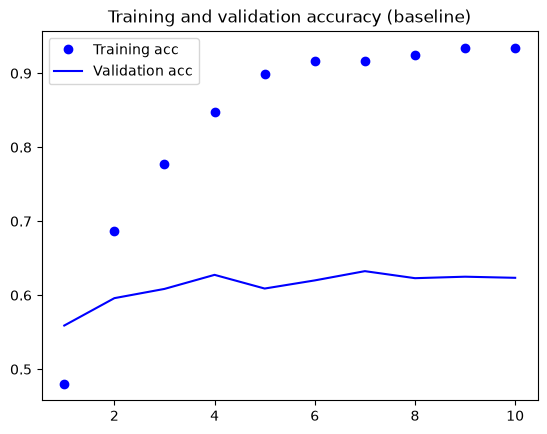

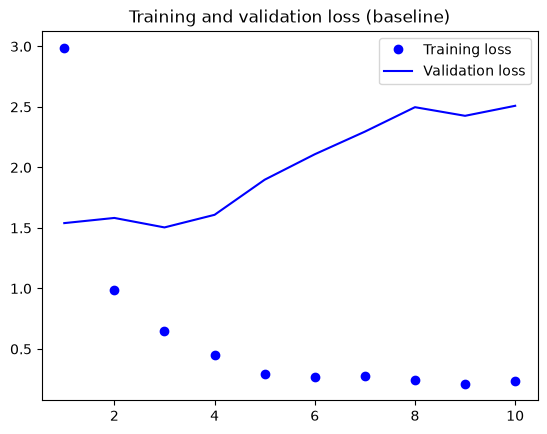

In [35]:
# Plot the Training and Validation Accuracy & Loss Scores
plot_curves(history, 'baseline')

#### Attempt 1: add dropout (0.3)

In [22]:
bModeld = models.Sequential()

bModeld.add(Input(shape=(3 * 3 * 512, )))
bModeld.add(layers.Dense(256, activation='relu'))
bModeld.add(layers.Dropout(0.3))
bModeld.add(layers.Dense(10, activation='softmax'))

bModeld.compile(optimizer='adam', 
               loss='sparse_categorical_crossentropy', 
               metrics=['acc'])

historyD = bModeld.fit(train_feats, train_labels,
                     epochs=10,
                     batch_size=20,
                     validation_data=(val_feats, val_labels))

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - acc: 0.3613 - loss: 3.3945 - val_acc: 0.4770 - val_loss: 1.6023
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - acc: 0.5111 - loss: 1.4945 - val_acc: 0.5525 - val_loss: 1.4552
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - acc: 0.5720 - loss: 1.3235 - val_acc: 0.5945 - val_loss: 1.3326
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - acc: 0.6272 - loss: 1.1260 - val_acc: 0.6090 - val_loss: 1.3813
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - acc: 0.6541 - loss: 1.0305 - val_acc: 0.6000 - val_loss: 1.3906
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - acc: 0.6873 - loss: 0.9413 - val_acc: 0.6145 - val_loss: 1.3932
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - acc: 0.7107 - loss: 0.8334 - val_acc: 0.6340 - val_loss: 1.4759
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - acc: 0.7257 - loss: 0.7867 - val_acc: 0.6155 - val_loss: 1.5007
Epoch 9/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/st

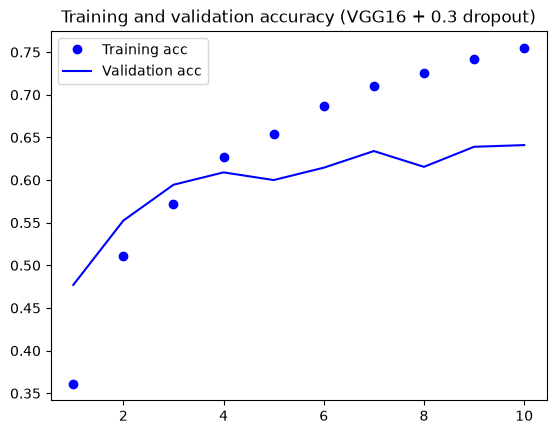

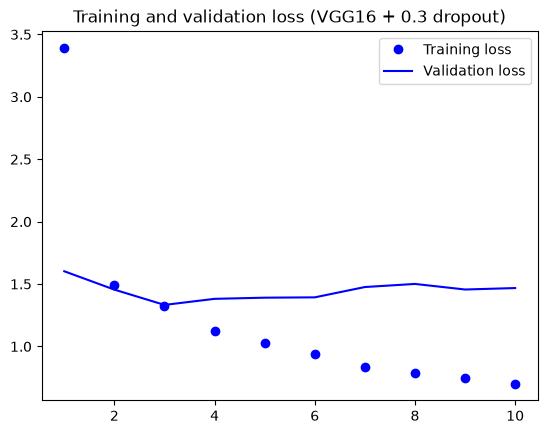

In [36]:
# Plot the Training and Validation Accuracy & Loss Scores
plot_curves(historyD, 'VGG16 + 0.3 dropout')

#### Attempt 2: unfreeze from block5_conv1 + data augmentation

In [24]:
def aug_and_preprocess(images, targets):
    for layer in data_augmentation_layers:
        images = layer(images, training=True)
    images = preprocess_input(images)
    return images, targets

train_dataset_p = train_dataset.map(aug_and_preprocess, num_parallel_calls=8)
val_dataset_p = validation_dataset.map(lambda x, y: (preprocess_input(x), y))

In [ ]:
bModelU = models.Sequential()

conv_base.trainable = True
set_trainable = False

for layer in conv_base.layers:
    if layer.name == 'block5_conv1':
        set_trainable = True # after block5_conv1, set_trainable becomes True
    if set_trainable:
        layer.trainable = True
    else:
        layer.trainable = False

bModelU.add(conv_base)
bModelU.add(layers.Flatten())
bModelU.add(layers.Dense(256, activation='relu'))
bModelU.add(layers.Dropout(0.4))
bModelU.add(layers.Dense(10, activation='softmax'))

bModelU.summary()

bModelU.compile(optimizer=optimizers.Adam(learning_rate=1e-5), 
               loss='sparse_categorical_crossentropy', 
               metrics=['acc'])

early_stop = EarlyStopping(monitor='val_acc', mode='max', patience=8, restore_best_weights=True)

historyU = bModelU.fit(train_dataset_p,
                     epochs=30,
                     validation_data=val_dataset_p,
                     callbacks=[early_stop])

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,897,162 (60.64 MB)

 Trainable params: 8,261,898 (31.52 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

Epoch 1/30


c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


375/375 ━━━━━━━━━━━━━━━━━━━━ 263s 691ms/step - acc: 0.1185 - loss: 5.0651 - val_acc: 0.1300 - val_loss: 2.3935
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 252s 671ms/step - acc: 0.1363 - loss: 2.3229 - val_acc: 0.1570 - val_loss: 2.2503
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 248s 662ms/step - acc: 0.1652 - loss: 2.2436 - val_acc: 0.2115 - val_loss: 2.1571
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 247s 658ms/step - acc: 0.2119 - loss: 2.1557 - val_acc: 0.2750 - val_loss: 2.0501
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 246s 657ms/step - acc: 0.2653 - loss: 2.0569 - val_acc: 0.3440 - val_loss: 1.9198
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 241s 643ms/step - acc: 0.3255 - loss: 1.9290 - val_acc: 0.4165 - val_loss: 1.7230
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 244s 650ms/step - acc: 0.3951 - loss: 1.7341 - val_acc: 0.5020 - val_loss: 1.5124
Epoch 8/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 244s 649ms/step - acc: 0.4637 - loss: 1.5687 - val_acc: 0.5540 - val_loss: 1.3423
Epoch 9/30
375/375 ━━━━━━━━━━━━━━━━

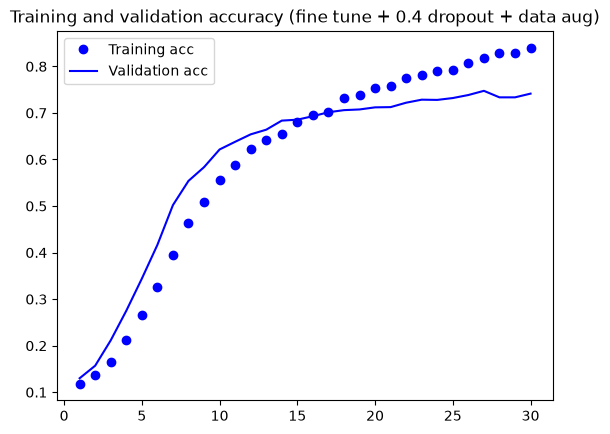

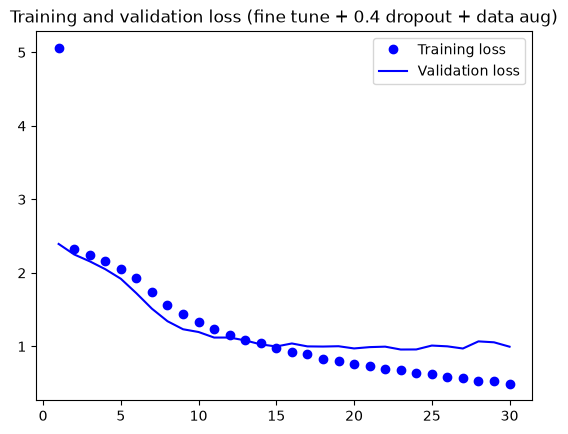

In [37]:
# Plot the Training and Validation Accuracy & Loss Scores
plot_curves(historyU, 'fine tune + 0.4 dropout + data aug')

In [29]:
historyU2 = bModelU.fit(train_dataset_p,
                        epochs=20,
                        validation_data=val_dataset_p,
                        callbacks=[early_stop])

Epoch 1/20


c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


375/375 ━━━━━━━━━━━━━━━━━━━━ 463s 1s/step - acc: 0.8211 - loss: 0.5413 - val_acc: 0.7270 - val_loss: 1.0329
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 370s 988ms/step - acc: 0.8323 - loss: 0.5140 - val_acc: 0.7330 - val_loss: 1.0338
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 254s 678ms/step - acc: 0.8371 - loss: 0.5029 - val_acc: 0.7440 - val_loss: 0.9722
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 252s 672ms/step - acc: 0.8488 - loss: 0.4685 - val_acc: 0.7340 - val_loss: 1.0634
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 252s 672ms/step - acc: 0.8527 - loss: 0.4604 - val_acc: 0.7500 - val_loss: 0.9597
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 251s 670ms/step - acc: 0.8585 - loss: 0.4371 - val_acc: 0.7420 - val_loss: 1.0318
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 264s 705ms/step - acc: 0.8597 - loss: 0.4322 - val_acc: 0.7455 - val_loss: 1.0876
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 354s 944ms/step - acc: 0.8668 - loss: 0.4110 - val_acc: 0.7450 - val_loss: 1.0333
Epoch 9/20
375/375 ━━━━━━━━━━━━━━━━━━━

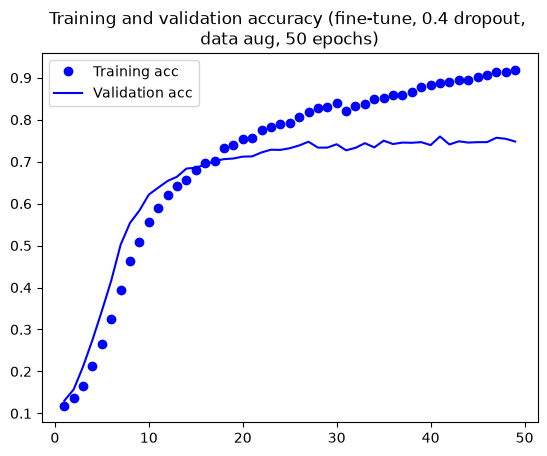

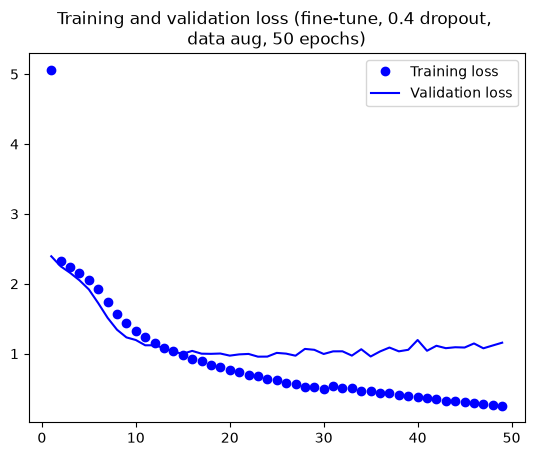

In [38]:
combined ={
    k: historyU.history[k] + historyU2.history[k]
    for k in historyU.history}
plot_curves(combined,'fine-tune, 0.4 dropout, \ndata aug, 50 epochs')

In [39]:
bModelU.evaluate(val_dataset_p)

100/100 ━━━━━━━━━━━━━━━━━━━━ 57s 566ms/step - acc: 0.7600 - loss: 1.0414


[1.0413557291030884, 0.7599999904632568]

**Attempt 3:** 0.5 dropout + GAP + l2 + lesser unfrozen layers

In [63]:
conv_base2 = VGG16(weights='imagenet', include_top=False, 
                  input_shape=(img_size,img_size,3))

conv_base2.trainable = True
set_trainable = False

for layer in conv_base2.layers:
    if layer.name == 'block5_conv3':  #unfreeze lesser than prev
        set_trainable = True 
    if set_trainable:
        layer.trainable = True
    else:
        layer.trainable = False

bModelU2 = models.Sequential()
bModelU2.add(conv_base2)
bModelU2.add(layers.GlobalAveragePooling2D())   #cut params
bModelU2.add(layers.Dropout(0.5))
bModelU2.add(layers.Dense(256, kernel_regularizer=l2(1e-4), activation='relu'))
bModelU2.add(layers.Dropout(0.5))
bModelU2.add(layers.Dense(10, activation='softmax'))

bModelU2.summary()

bModelU2.compile(optimizer=optimizers.Adam(learning_rate=1e-5), 
               loss='sparse_categorical_crossentropy', 
               metrics=['acc'])

early_stop2 = EarlyStopping(monitor='val_acc', patience=10, restore_best_weights=True)
reduce_lr2 = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-7)

historyU3 = bModelU2.fit(train_dataset_p,
                         epochs=40,
                         validation_data=val_dataset_p,
                         callbacks=[early_stop2, reduce_lr2])

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,586 (56.64 MB)

 Trainable params: 2,493,706 (9.51 MB)

 Non-trainable params: 12,354,880 (47.13 MB)

Epoch 1/40


c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


375/375 ━━━━━━━━━━━━━━━━━━━━ 365s 957ms/step - acc: 0.1195 - loss: 15.4614 - val_acc: 0.1910 - val_loss: 4.9362 - learning_rate: 1.0000e-05
Epoch 2/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 487s 1s/step - acc: 0.1468 - loss: 8.7744 - val_acc: 0.2595 - val_loss: 3.2991 - learning_rate: 1.0000e-05
Epoch 3/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 267s 710ms/step - acc: 0.1667 - loss: 6.0664 - val_acc: 0.2835 - val_loss: 2.6966 - learning_rate: 1.0000e-05
Epoch 4/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 260s 693ms/step - acc: 0.1740 - loss: 4.6107 - val_acc: 0.2990 - val_loss: 2.3644 - learning_rate: 1.0000e-05
Epoch 5/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 263s 702ms/step - acc: 0.1793 - loss: 3.9072 - val_acc: 0.3055 - val_loss: 2.1897 - learning_rate: 1.0000e-05
Epoch 6/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 265s 707ms/step - acc: 0.1809 - loss: 3.3967 - val_acc: 0.3310 - val_loss: 2.0765 - learning_rate: 1.0000e-05
Epoch 7/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 390s 1s/step - acc: 0.1929 - loss: 3.0327 - val_acc: 0.3375 - val_loss: 2

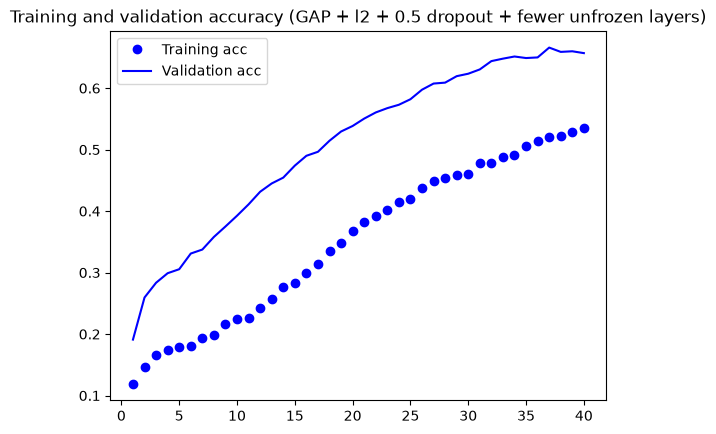

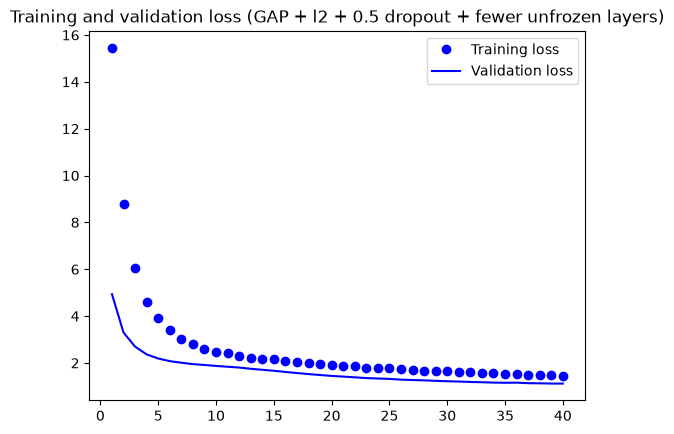

In [64]:
plot_curves(historyU3, 'GAP + l2 + 0.5 dropout + fewer unfrozen layers')

In [66]:
bModelU2.evaluate(val_dataset_p)

100/100 ━━━━━━━━━━━━━━━━━━━━ 40s 398ms/step - acc: 0.6660 - loss: 1.1365


[1.1365004777908325, 0.6660000085830688]

Continue letting bModelU2 train.

In [69]:
bModelU2.compile(optimizer=optimizers.Adam(learning_rate=5e-5),
                 loss='sparse_categorical_crossentropy',
                 metrics=['acc'])

early_stop3 = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
reduce_lr3 = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7)

historyU4 = bModelU2.fit(train_dataset_p, 
                         epochs=40, 
                         validation_data=val_dataset_p, 
                         callbacks=[early_stop3, reduce_lr3])

Epoch 1/40


c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


375/375 ━━━━━━━━━━━━━━━━━━━━ 239s 629ms/step - acc: 0.5260 - loss: 1.5057 - val_acc: 0.6450 - val_loss: 1.1442 - learning_rate: 5.0000e-05
Epoch 2/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 266s 707ms/step - acc: 0.5341 - loss: 1.4745 - val_acc: 0.6610 - val_loss: 1.1023 - learning_rate: 5.0000e-05
Epoch 3/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 253s 674ms/step - acc: 0.5512 - loss: 1.4228 - val_acc: 0.6625 - val_loss: 1.0867 - learning_rate: 5.0000e-05
Epoch 4/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 229s 609ms/step - acc: 0.5699 - loss: 1.3538 - val_acc: 0.6850 - val_loss: 1.0377 - learning_rate: 5.0000e-05
Epoch 5/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 229s 608ms/step - acc: 0.5832 - loss: 1.3268 - val_acc: 0.6900 - val_loss: 1.0292 - learning_rate: 5.0000e-05
Epoch 6/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 223s 595ms/step - acc: 0.6005 - loss: 1.2624 - val_acc: 0.6900 - val_loss: 1.0255 - learning_rate: 5.0000e-05
Epoch 7/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 250s 562ms/step - acc: 0.6092 - loss: 1.2535 - val_acc: 0.6970 - val_lo

In [70]:
combined2 = {
    k: historyU3.history[k] + historyU4.history[k]
    for k in historyU3.history}

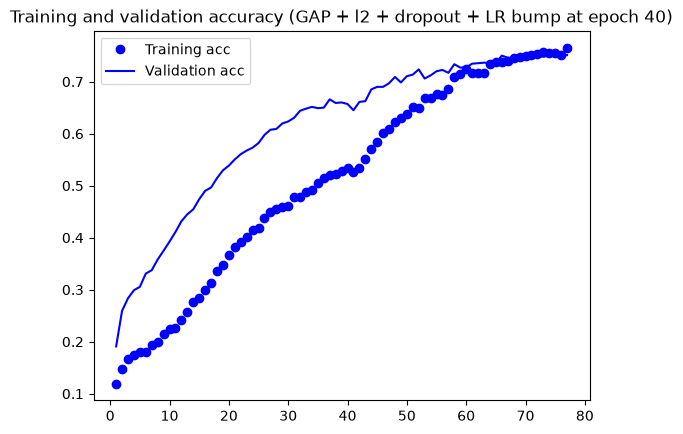

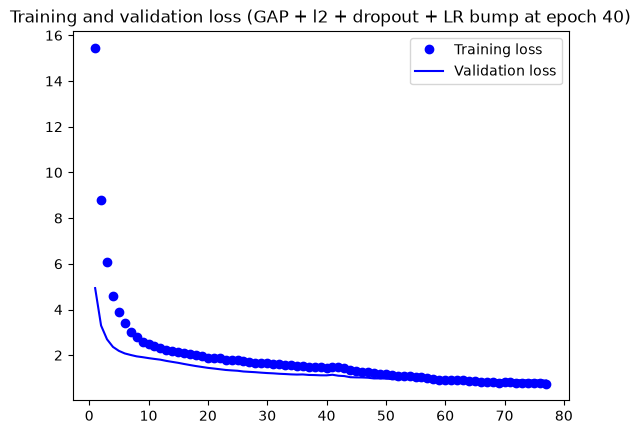

In [71]:
plot_curves(combined2,'GAP + l2 + dropout + LR bump at epoch 40')

In [72]:
bModelU2.evaluate(val_dataset_p)

100/100 ━━━━━━━━━━━━━━━━━━━━ 38s 376ms/step - acc: 0.7460 - loss: 0.8856


[0.8855626583099365, 0.7459999918937683]

In [73]:
# Save the Model
path2 = os.path.join(base_dir, 'food_model_2.h5')
bModelU2.save(path2)

## Step 3 – Evaluate the Developed Models using Testing Images

In [52]:
# Model #1
pathE1 = os.path.join(base_dir,'food_model_1.h5')
model1 = keras.models.load_model(pathE1)
test_loss1, test_acc1 = model1.evaluate(test_dataset)
print(f'Model 1 (scratch CNN): test acc: {test_acc1:.4f}, test loss: {test_loss1:.4f}')

25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - acc: 0.4700 - loss: 1.6414
Model 1 (scratch CNN): test acc: 0.4700, test loss: 1.6414


In [74]:
# Model #2
pathE2 = os.path.join(base_dir,'food_model_2.h5')
model2 = keras.models.load_model(pathE2)

test_dataset_p = test_dataset.map(lambda x, y: (preprocess_input(x), y))

test_loss2, test_acc2 = model2.evaluate(test_dataset_p)
print(f'Model 2 (VGG16): test acc: {test_acc2:.4f}, test loss: {test_loss2:.4f}')

25/25 ━━━━━━━━━━━━━━━━━━━━ 13s 461ms/step - acc: 0.7080 - loss: 0.8987
Model 2 (VGG16): test acc: 0.7080, test loss: 0.8987


In [75]:
# Save the best model
pathBest = os.path.join(base_dir, 'food_model_best.h5')
bModelU2.save(pathBest)

## Step 4  – Use the best model to make prediction

In [4]:
# Load the model
pathP = os.path.join(base_dir,'food_model_best.h5')
modelP = keras.models.load_model(pathP)

In [5]:
# Load the food list (in alphabetical order)
with open(r"C:\Users\jaeth\Downloads\NP\Y2S1\DL\DL ASG\Food_list\Food_list\17.txt", 'r') as f: # the .txt file which contains a list of food assigned to you
    x = f.readlines()
food_list =[]
for item in x:
    food_list.append(item.strip('\n'))
food_list = sorted(food_list) # food_list needs to be sorted alphabetically before feed into prediction() function
print(food_list)

['apple_pie', 'baby_back_ribs', 'breakfast_burrito', 'chocolate_cake', 'cup_cakes', 'eggs_benedict', 'escargots', 'falafel', 'risotto', 'sushi']


In [6]:
# Define some related functions for image process and model prediction
from keras.preprocessing.image import load_img, img_to_array
def image_process(img):
    image = load_img(img, target_size =(img_size, img_size))
    image_array = img_to_array(image)
    image_array = preprocess_input(image_array)
    return image_array

import pandas as pd
def prediction(model, img_array, items_l):
    prob = model.predict(img_array.reshape(1,img_size,img_size,3))
    pro_df = pd.DataFrame(prob, columns = items_l)
    result = items_l[np.argmax(prob)]
    return pro_df, result

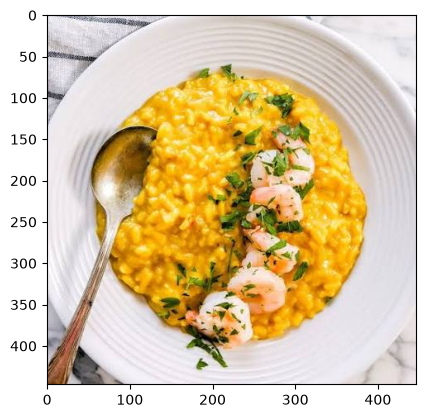

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
The prediction is:  risotto 

    apple_pie  baby_back_ribs  breakfast_burrito  chocolate_cake     cup_cakes  \
0   0.000035        0.000005           0.000063    6.643377e-07  4.816355e-07   

   eggs_benedict  escargots  falafel   risotto     sushi  
0       0.000012   0.000228  0.00032  0.999331  0.000005  



In [31]:
# Make prediction for the image you downloaded from internet

img = r"C:\Users\jaeth\Downloads\images.jpg"  # the picture you downloaded from internet, which contains a type of food in your food list

plt.imshow(plt.imread(img))
plt.show()

img_array = image_process(img)
prob_df, result = prediction(modelP, img_array, food_list)
print('The prediction is: ', result, '\n\n', prob_df)
print()

Trying with another image (chocolate cake)

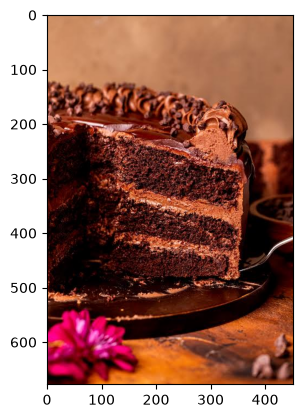

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
The prediction is:  chocolate_cake 

       apple_pie  baby_back_ribs  breakfast_burrito  chocolate_cake  \
0  1.875783e-12    2.176131e-10       2.421307e-16             1.0   

      cup_cakes  eggs_benedict     escargots       falafel       risotto  \
0  9.979818e-13   2.066977e-20  1.331989e-17  1.419805e-14  1.180331e-14   

          sushi  
0  1.006266e-11  



In [32]:
img = r"C:\Users\jaeth\Downloads\images (1).jpg"

plt.imshow(plt.imread(img))
plt.show()

img_array = image_process(img)
prob_df, result = prediction(modelP, img_array, food_list)
print('The prediction is: ', result, '\n\n', prob_df)
print()

Cup cakes this time since both chocolate cake and cup cakes have similar traits. I chose a chocolate cup cake to see if my model can make that distinction without the hint of their colours.

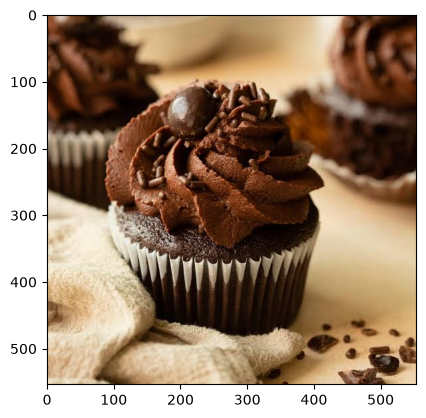

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
The prediction is:  cup_cakes 

       apple_pie  baby_back_ribs  breakfast_burrito  chocolate_cake  cup_cakes  \
0  8.862426e-14    1.928295e-14       3.454270e-14    1.047542e-09        1.0   

   eggs_benedict     escargots       falafel       risotto         sushi  
0   3.387738e-21  1.015463e-19  1.788058e-17  1.317924e-23  4.278916e-14  



In [33]:
img = r"C:\Users\jaeth\Downloads\images (2).jpg"

plt.imshow(plt.imread(img))
plt.show()

img_array = image_process(img)
prob_df, result = prediction(modelP, img_array, food_list)
print('The prediction is: ', result, '\n\n', prob_df)
print()

<hr>

# Report
<hr>

## Overview
This assignment's individual portion's task is to **build an image classification model capable of recognising and classifying 10 different categories of food from a selected portion of the Food-101 dataset assigned to me.** <br><br>
The 10 assigned classes (17.txt) are apple pie, baby back ribs, breakfast burrito, chocolate cake, cup cakes, eggs benedict, escargots, falafel, risotto, and sushi. <br>

The **objective** was not to just build a working image classifier, but to also demonstrate an understanding of the universal machine learning workflow. Which is to build a baseline model, purposely scale it till it overfits, and finally regularising it back down to a well performing model while justifying each decision with evidence from the training and validation curves plotted and metrics. <br>

Many of the food categories have overlapping colours, textures, and shapes (for example: cup cakes and chocolate cake), so the ideal model needs to learn intricate visual features instead of relying on general distinctions like colour. <br>

Since the dataset is quite small with 750 training, 200 validation, and 50 test images per class (10 classes), training a convolutional network from scratch is not an ideal approach, as it will unlikely generalise well. Since there is not enough data for a network to learn well on its own, I will try exploring 2 different approaches. <br><br>

**Approach 1: Building a CNN from scratch** <br>
I built a CNN from scratch to get a rough idea of what a model without any prior knowledge, visual wise, can achieve with this dataset. It also allowed me to practise correcting through regularisation. <br>

**Approach 2: Transfer learning with VGG16**<br>
I first used the convolutional network that was pretrained on ImageNet to extract the features for the 10 classes. Following that, I then fine tuned the model on the food dataset that I was provided. Since VGG16 has already learnt the general features like edges, shapes, and textures from 1.4 million images, it gives a stronger base for a small dataset like the one we were provided with. <br><br>

Both the approaches follow the same workflow of: build baseline -> overfit -> regularise. This allowed direct comparison between learning the features from scratch against using a pretrained network. <br>

All the images were resized to (100x100) instead of (150x150) to keep my training time more manageable, since larger inputs made feature extraction and fine tuning very slow on my computer (local hardware).
<hr>

## Data Preprocessing and Data Loading
Using the provided image processing script, it read the assigned class list from my assigned .txt file (17) and copied the corresponding images from the Food-101 dataset into 3 separate folders (train, validation, and test) with a split of 750, 200, and 50 images per class respectively. This gave me 7500 training images, 2000 validation images, and 500 test images from the 10 different classes, with each class in their own subfolder. <br>

All the images in the 3 folders were then loaded into the Jupyter notebook with `image_dataset_from_directory` from Keras' utility. The function read images directly from their folder and inferred class labels from their subfolder names. This allowed me to skip the step of manually creating a labelled dataset.

All images were then resized to 100x100 instead of 150x150, to keep feature extraction and training time more manageable, since running the training with inputs the size of 150x150 were taking too long to be practical with iterating through multiple attempts at tuning the hyperparameters. The images were then loaded into batches of 20. <br>

Since VGG16 requires inputs to be preprocessed, the Keras function, `preprocess_input`, was applied to every batch before it passed through the its convolutional base. This **preprocessing was used in 2 different ways** in the different stages of the workflow. <br>

- **Feature extraction stage**: During this stage, `preprocess_input()` was applied to each batch of images before they passed through `conv_base.predict()` to extract the feature maps. <br>

- **Fine tuning**: During fine tuning, where the model has to see the augmented images on every epoch, preprocessing was included as part of the transformation, `aug_and_preprocess`, so that augmentation and the normalisation that VGG16 inputs are required to have, occurred for every batch during training. <br><br>

For **Approach A** (CNN from scratch), a `Rescaling(1/255)` layer was used instead, since this CNN model does not rely on the specified ImageNet normalisation and only requires the pixel values to be scaled and range from 0-1. <br>

To create more diversity and variety within the given dataset, **data augmentation**, specifically random horizontal flips, ±10% rotation, and 20% zooms were introduced, only from the second attempt onwards for **both approaches**. It was implemented as a list of preprocessing layers applied through `dataset.map()`. This was done to reduce overfitting once the baseline models of both approaches shows signs of deteriorating training and validation performance. 
<br><hr>

## Develop the Image Classification Models
Since I followed the universal machine learning workflow, both approaches utilise the same structure. 

### Model 1 - Convolutional Neural Network trained from scratch
**Baseline (no regularisation)**: I built a simple CNN with four convolution and max-pooling blocks (32 > 64 > 128 > 128 filters, 3x3 kernels, and ReLU as the activation function). Followed by a `Flatten()` layer, a dense layer with 256-units, and a 10-unit softmax output layer. Giving me a total of 767,946 trainable parameters. To compile the model, I used the Adam optimizer, loss as sparse categorical cross-entropy, and trained the network with 20 epochs. This was done without any data augmentation or dropouts. 

**Results:** The model almost immediately overfitted. By the 20th epoch, training accuracy reached **94.2%** with its loss at **0.18**. While validation accuracy quickly plateaued around `epochs=6` and declined to **37.8%** with its validation loss climbing sharply to **4.79**. This large gap between the training and validation metric is an obvious sign of overfitting, where the model starts memorising the training images rather than learning the generalised features. However, this is not surprising since these are the results from a CNN with no prior visual knowledge and only 750 images a class to learn from. <br><br>

#### Model 1 - **Attempt 1**: Data augmentation, 0.5 dropout, and lower learning rate
To reduce the overfitting, I **augmented the data** with random flips, rotations, and zooms on the training dataset. I also added a dropout layer with a rate of **0.5** before the final dense layer and used a lower rate of **1e-4** to stabilise training over the larger epoch (30). 

**Results:** This closed the gap between training and validation results quite well. At epoch 30, training accuracy was **53.4%** and training loss at **1.36** and validation accuracy at **42.2%** with validation loss at **1.86**. While the gap between the sets' accuracy decreased a lot compared to the baseline, the overall accuracy was still low. This suggests that the regularisation was strong enough to prevent memorisation but too strong that the network either under-trained, or under-utilised its capacity. <br><br>

#### Model 1 - **Attempt 2**: Decrease dropout (0.3) and EarlyStopping
Since dropout at 0.5 together with data augmentation seemed to slow the model's training without meaningfully improving the validation accuracy, I decided to reduce the dropout rate to 0.3 and add `EarlyStopping` callback to monitor `val_loss`, with a patience of 8 epochs, and to restore the best weights, to avoid wasting epochs once the model stopped improving. I gave the model up to 50 epochs. 

**Results:** Given up to 50 epochs, `EarlyStopping` stopped the model's training at epoch 23. Training accuracy stopped at **53.3%** and validation accuracy increased to **45.5%** from the earlier **42.2%**. Train loss stopped at **1.37** and validation loss at **1.72**. This demonstrates that the lighter dropout rate combined with the early stoppage made an improvement in the model's generalisation ability. <br><br>

#### Model 1 - **Attempt 3**: L2 regularisation + 0.3 dropout + ReduceLROnPlateau + EarlyStopping
I added L2 weight regularisation (1e-4) to every convolutional layer and kept the dropout at 0.3, but now applied after both the flatten and dense layers. I also added a  `ReduceLROnPlateau` callback to automatically reduce the learning rate when the validation stagnated and `EarlyStopping` monitoring `val_acc` instead of `val_loss` with a patience of 10. 

**Results:** I gave the model 60 epochs to train with but it stopped at **epochs=27** with the learning rate reduced to **2.5e-5**. Final metrics were training accuracy = 52.5%, validation accuracy = 43.6%, and training loss = 1.39, validation loss = 1.75. These results are very close to attempt 2's results, with validation accuracy staying within the 43-46% ranges instead of falling like it did in the baseline model. 

Evaluating this model on the augmented training set afterwards gave an accuracy of **49.5%** and a loss of **1.50**, close to the validation figure, showing that the overfitting gap had been closed, even though the accuracy ceiling achievable from building a model from scratch remains limited. This model (`sModelAug3`) was saved as `food_model_1.h5`. <br><hr>

### Model 2 - Transfer Learning with VGG16
**Feature extraction:** Instead of training convolutional filters from scratch, I used VGG16's convolutional base with ImageNet weights and an input shape of (100x100x3), giving 14.7 million parameters, as a fixed feature extractor. Every image in the three sets were passed through `preprocess_input()`, then through the frozen convolutional base to produce a (3x3x512) feature map per image, and flattened into a 4608-dimensional feature vector. This lets the classifier head learn from these semantically-rich features rather than the raw pixels the images initially possessed. <br><br>

**Baseline dense head with no regularisation:** I built a simple classifier head. This included one 256-unit dense layer with ReLU activation, followed by a 10-unit softmax output layer, giving me 1.18 million trainable parameters to work with. 
 
**Results:** This baseline model overfitted almost immediately, given the features already contained the most beneficial data of the images. By epoch 10, the training accuracy reached **93.5%** while validation accuracy plateaued around **62.4%**, with validation loss rising from around 1.5 to **2.51** even as training loss fell all the way to 0.24. This is the same overfitting pattern I observed in Approach 1's baseline CNN, just starting from a higher accuracy due to VGG16's pretrained features. <br><br>

#### Model 2 - **Attempt 1**: 0.3 dropout
I added a 0.3 dropout layer right before the output layer to reduce the overfitting gap. 

**Results:** By epoch 10, training accuracy was 75.5% and validation accuracy at 64.1%, an improvement of ~2 percentage points over the baseline, with a visibly smaller train/val gap and slower-rising validation loss (1.47). This showed me that dropout is capable of giving low-cost improvements when working with pretrained features. <br><br>

#### Model 2 - **Attempt 2**: Fine-tuning (unfreeze from `block5_conv1`) + data augmentation + 0.4 dropout
For further improvements, I unfroze the top convolutional block from block5_conv1 onwards, so those layers could optimize their filters to specifically the food images, while keeping the earlier and more generic layers, that has learnt features like edges and textures, frozen. I combined this with data augmentation, applied with `dataset.map()` before `preprocess_input()` and an increased dropout rate of 0.4 before the output layer. A lower learning rate of 1e-5 was used to avoid destroying the pretrained weights, together with  `EarlyStopping` (monitoring `val_acc`, patience=8). Since fine-tuning requires every augmented image to pass through the entire convolutional base each epoch, the pre-extracted static features could not be used and the convolution base had to be trained again, making the time for each epoch slower (ranging from ~250-450s per epoch versus a few seconds for the cnn built with dense-head-only models) 

**Results**: Training initially ran across 30 epochs, but I added another 20 epochs that continued with the first session's weights. As a result, training accuracy hit **91.95%**, while validation accuracy peaked around **75.5%** but stabilised between 74-76%. Evaluating this model on the full validation set gave **76.0%** accuracy and **1.041** loss. <br>

I chose to monitor `val_acc` instead of `val_loss` in this attempt because I noticed validation loss climbing slighting while validation accuracy kept improving. Showing me that the model was becoming more confident in its predictions instead of becoming less accurate. Since this assignment's evaluation ultimately cares about classification accuracy, monitoring `val_loss` in early stopping would have probably stopped the training too early and left accuracy improvements unused. 

However, training accuracy hit around **92%**, well above the validation accuracy of ~**76%** (around 16 percentage point gap). So even though attempt 2 achieved the highest raw validation accuracy so far, its plot showed obvious signs of overfitting, just at a much higher accuracy level compared to the CNN built from scratch. Seeing that, my goal for the following attempt was to close this overfitting gap instead of chasing an even higher raw accuracy. <br><br>

#### Model 2 - **Attempt 3**: New conv base + lesser unfrozen layers + Global Average Pooling 2D (instead of Flatten) + L2 + 0.5 dropout
I rebuilt the VGG16 convolutional base (`conv_base2`) and unfroze only from `block5_conv3` onwards (fewer layers) rather than from `block5_conv1`, so less of the pretrained network was retrained. I also swapped out `Flatten()` with `GlobalAveragePooling2D()`, which significantly cut the number of parameters fed to the dense head and also acts as a form of regularisation. L2 regularisation (1e-4) was added to the dense layer with a heavier dropout (0.5). The model was compiled with a lower learning rate of 1e-5, and trained with `EarlyStopping` (monitoring `val_acc`, patience=10) and `ReduceLROnPlateau` (monitoring `val_loss`, factor=0.5, patience=4).

**Results**: The first training phase used all 40 epochs without `EarlyStopping` triggering, and ended with a training accuracy at **53.5%** and **65.7%** validation accuracy, with the best validation accuracy at **66.6%** (val_loss=1.14) at epochs=37 (the model's best restored weights). <br>

Since val_acc was still climbing and hadn't plateaued yet, I gave it more time to train. I recompiled the model with a slightly higher learning rate (5e-5) and switched `EarlyStopping` back to monitor `val_loss` with patience=10, with `ReduceLROnPlateau` (patience=3), for another 40 epochs. This resulted in `EarlyStopping` triggering at epoch 37, with a training accuracy reaching **76.6%** and loss of 0.76 and Validation accuracy at **75.1%** (loss 0.89), before the best weights were restored from the checkpoint with the lowest validation loss. The final evaluated results for this attempt was **74.6%** validation accuracy and a validation loss of **0.886**.

Comparison table of Model 2's **Attempt 2** and **Attempt 3**:
| | Attempt 2 (`bModelU`) | Attempt 3 (`bModelU2`) |
|---|---|---|
| Unfrozen from | `block5_conv1` | `block5_conv3` (fewer layers) |
| Pooling | Flatten | GlobalAveragePooling2D |
| Regularisation | 0.4 dropout | L2 (1e-4) + 0.5 dropout ×2 |
| Final train accuracy | ~92% | ~76.6% |
| Final val accuracy | 76.0% | 74.6–75.0% |
| Final val loss | 1.041 | **0.886** |
| Train–val accuracy gap | ~16 pp | **~1–2 pp** |

It may look like attempt 3 made the same validation accuracy as attempt 2 and even performed worse. But viewing the results that way leaves out on a more important result, which is that validation loss dropped by about 15%, making the train-validation accuracy gap basically disappear. In attempt 2, training accuracy overtook its validation accuracy by 16 percentage points (overfitting). Whereas in attempt 3, training and validation accuracy followed one another closely across the whole second phase of training. 

This makes the outcomes of attempt 2 and 3 different. Attempt 3 traded a small amount of training accuracy for a model that is better at generalising. Given the comparable accuracy, Attempt 3 is the model I would trust more on unseen data, since it is better calibrated and shows no meaningful sign of overfitting. The combination of a fresh conv base with fewer unfrozen layers, GAP instead of Flatten, and strong L2 and dropout regularisation proved to fix the overfitting problem observed in attempt 2, even though it did not improve its raw accuracy. 

Since `bModelU2` (attempt 3) has the smaller generalisation gap and lower validation loss, I decided to use this attempt as Model 2 for the testing portion of this assignment. 
<hr>

### Table of model development
| Model | Configuration | Final train acc | Final val acc | Final val loss |
|---|---|---|---|---|
| 1 – Baseline (scratch CNN) | No regularisation, 20 epochs | 94.2% | 37.8% | 4.79 |
| 1 – Attempt 1 | +Augmentation, 0.5 dropout | 53.4% | 42.2% | 1.86 |
| 1 – Attempt 2 | 0.3 dropout + EarlyStopping | 53.3% | 45.5% | 1.72 |
| 1 – Attempt 3 (final, saved) | +L2 reg, ReduceLROnPlateau | 52.5% | 43.6% | 1.75 |
| 2 – Baseline (VGG16 dense head) | No regularisation, 10 epochs | 93.5% | 62.4% | 2.51 |
| 2 – Attempt 1 | +0.3 dropout | 75.5% | 64.1% | 1.47 |
| 2 – Attempt 2 | Unfreeze block5_conv1 + aug + 0.4 dropout | ~92.0% | 76.0% | 1.04 |
| 2 – Attempt 3 (saved as best) | Unfreeze block5_conv3 + GAP + L2 + 0.5 dropout | ~76.6% | 74.6–75.0% | **0.89** |
---

## Evaluate tuned model using Test Images
After identifying the best version of the 2 approaches, the models were evaluated on the held-out test set of 500 images (50 per class) that was kept away during training and validation. 

**Results**:
| Model | Description | Test Acc | Test Loss |
|---|---|---|---|
| Model 1 | Scratch CNN | 47.0% | 1.64 |
| Model 2 | Transfer Learning | **70.8%** | **0.899** |

The model with transfer learning clearly outperformed the from-scratch CNN on the test set (70.8% vs 47.0%) with a gap of almost 24 percentage points. This supports the earlier reasoning that transfer learning would be necessary given the small dataset. Model 1's test accuracy of 47.0% is reasonably close to its validation accuracy (43.6%), which shows that the regularisation applied earlier successfully closed the overfitting gap, even though the model's ideal performance is held back by the small dataset and lack of prior visual knowledge. On the other hand, VGG16's convolutional base already learnt the generic lower level visual features from the 1.4 million images from ImageNet, making fine tuning only the last few more task-specific layers an easier learning problem. 

Model 2's results also tell us more about the comparison I made between attempt 2 and attempt 3 in its development. Attempt 3's test accuracy came in at 70.8% which is about 4 percentage points lower than attempt 2's 74.8%. So the trade-off is not entirely free as attempt 3's much smaller train-validation gap and lower validation loss did not really carry over into a test-accuracy advantage. If anything, attempt 2 still does better with its raw test accuracy. While attempt 3 remains the better calibrated model with better generalisation, but the "smaller generalisation gap" and "higher test accuracy" are not automatically the same thing. It ultimately depends on what the task is. 

That said, I saved attempt 3 as `food_model_best.h5`.
<br><hr>

## Using the model to perform classification
To use `food_model_best.h5` on images from the Internet, each image has to be resized to 100x100 and preprocessed the same way, using `preprocess_input()`, before `model.predict()` runs. The output will be the probability for each of the 10 classes. The class which holds the highest predicted probability will be read as the model's prediction. That said, here are the predictions for the 3 images I downloaded from the Internet:
| Image | Actual Class | Prediction | Confidence |
|---|---|---|---|
| Risotto | risotto | risotto | 99.9% |
| Chocolate cake | chocolate_cake | chocolate_cake | ~100% |
| Chocolate cup cake | cup_cakes | cup_cakes | ~100% |

Predictions on the three separate unseen images all came out right with very high confidence.

I deliberately chose chocolate cup cakes as the third image to specifically test whether the model could tell cup cakes apart from chocolate cake, without relying on colour as a short cut, since these 2 classes can look similar like I stated earlier in the **Overview**. The model correctly classified the cup cakes with extremely high confidence, suggesting it has genuinely learnt the distinctive shape and texture features for these classes instead of just their colour. That said, 3 images is still a small sample size. So while seeing how the model performed with just the three is reassuring, it should not be read as overriding the 70.8% test accuracy that was properly measured across the full test set (500 images). <hr>

## Summary 
Following the universal machine learning workflow, the model that utilised transfer learning with VGG16 clearly outperformed the CNN trained from scratch on this food classification task (70.8% vs 47.0%). This gap shows the value of pretrained features when dealing with a small dataset. Even with a lot of regularisation (data augmentation, dropout, L2, EarlyStopping, and ReduceLROnPlateau), the from-scratch CNN was fundamentally limited by how much it could learn from the very little data available. Whereas, VGG16 only needed to change its last few laters using the knowledge it already had from its prior training. 

In the VGG16 approach itself, attempt 2 and 3 highlighted an important point beyond just raw accuracy. Attempt 3 achieved comparable validation accuracy to attempt 2 but with a much smaller train-validation gap and also a lower validation loss (0.886 vs 1.041). This establishes that the regularisation done in attempt 3, successfully addressed the overfitting issue identified in attempt 2. Although the smaller overfitting gap and better validation loss did not guarantee a higher accuracy on unseen data, the 2 attempts exemplify a real trade-off between calibration and generalisation behaviour against just raw accuracy.

For further improvement, I would first try to further reduce the small overfitting gap in attempt 3 by unfreezing slightly more layers in the convolutional base. Since attempt 3's train accuracy dropped from around 92% to 77% with no overfitting, it shows that it has spare capacity to use. This could recover some of the accuracy loss while maintaining its generalisation abilities. Second, I would increase the input resolution to 150x150 or even 224x224 since it is VGG16's native input. This would preserve more details that are useful for distinguishing visually similar classes. This will however also result in longer training time. 
<hr>